# Experiment: fitting attrition models with SINDy (Python 3.12 environment)

**Goal.** Discover compact equations for how each side's strength declines during a SMAC battle, test them against Lanchester's laws, and check whether they predict battles they weren't trained on.

**Variables** (all per step, in *marine units* so that coefficients are comparable across maps):

- `Ha`, `Hb`: total health of the allies / enemies divided by one marine's health (45). `Ha = 8` is a full 8-marine team.
- `Na`, `Nb`: number of living allies / enemies.

**Hypotheses** for ally losses per step (enemy losses are the mirror image):

| Model | Equation | Meaning |
|---|---|---|
| Square law | ΔHa = −β Nb | Aimed fire: each living enemy removes β marine-health per step |
| Linear law | ΔHa = −β Na Nb | Area fire: losses also scale with the number of targets |
| Pure decay | ΔHa = −c Ha | Losses proportional to own health: no physical interaction |

Under the square law, fighting strength is α·N², and the break-even force ratio is N_enemy / N_ally = √(α/β).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pysindy as ps

DATA = Path("../data/experiment")
HP_UNIT = 45.0                                   # health of one marine
KEY = ["map", "p_focus", "episode_id"]           # identifies one battle
rng = np.random.default_rng(0)

episodes = pd.concat([pd.read_csv(f) for f in sorted(DATA.glob("episodes_*.csv.gz"))], ignore_index=True)
units    = pd.concat([pd.read_csv(f) for f in sorted(DATA.glob("units_*.csv.gz"))],    ignore_index=True)
episodes["force_ratio"] = episodes.n_enemies / episodes.n_agents
print(f"{len(episodes)} battles, {len(units):,} unit rows")
episodes.groupby(["map", "p_focus"]).size().unstack()

3000 battles, 3,861,171 unit rows


p_focus,0.0,0.5,1.0
map,,,
10m_vs_11m,200,200,200
3m,200,200,200
5m_vs_6m,200,200,200
8m,200,200,200
8m_vs_9m,200,200,200


## 1. Outcomes: who wins?

The win rate against the force ratio is the simplest summary of the experiment. More enemies should lower the win rate, and more focus fire should raise it. We come back to this plot in section 7 and check whether the fitted equations predict where each curve crosses 50%.

,map,p_focus,force_ratio,win_rate,timeouts,mean_length
3,3m,0.0,1.00,0.00,0.0,60.00
9,8m,0.0,1.00,0.38,0.0,99.28
0,10m_vs_11m,0.0,1.10,0.00,0.0,83.30
12,8m_vs_9m,0.0,1.12,0.00,0.0,76.58
6,5m_vs_6m,0.0,1.20,0.00,0.0,67.58
4,3m,0.5,1.00,0.00,0.0,60.00
10,8m,0.5,1.00,0.80,0.0,101.64
1,10m_vs_11m,0.5,1.10,0.05,0.0,100.28
13,8m_vs_9m,0.5,1.12,0.03,0.0,91.96
7,5m_vs_6m,0.5,1.20,0.00,0.0,69.95


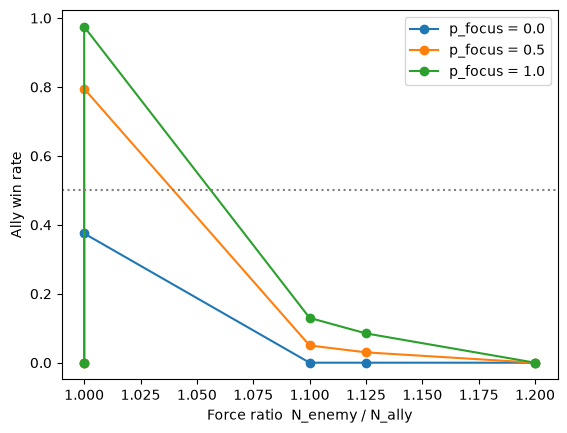

In [2]:
summary = (episodes.groupby(["map", "p_focus"])
                   .agg(force_ratio=("force_ratio", "first"), win_rate=("battle_won", "mean"),
                        timeouts=("timeout", "mean"), mean_length=("length", "mean"))
                   .reset_index().sort_values(["p_focus", "force_ratio"]))
display(summary.round(2))

fig, ax = plt.subplots()
for p, d in summary.groupby("p_focus"):
    ax.plot(d.force_ratio, d.win_rate, "o-", label=f"p_focus = {p}")
ax.axhline(0.5, color="grey", ls=":")
ax.set(xlabel="Force ratio  N_enemy / N_ally", ylabel="Ally win rate")
ax.legend(); plt.show()

## 2. From unit logs to battle trajectories

For every battle:

1. Sum health and count living units per team at every step, and convert to marine units.
2. **Start** one step before first contact (the first step where either side loses health). The approach phase has no attrition and would only confuse the fit.
3. **End** at the first step where one side is wiped out. After that, the dead side's health stays at zero, which contradicts the attrition terms.

Each battle becomes a state trajectory `X = [Ha, Hb]` and an input trajectory `U = [Na, Nb]`. Unit counts are treated as inputs rather than states: they follow from health, and including both as states made the library badly collinear in earlier fits.

In [3]:
agg = (units.groupby(KEY + ["t", "team"])
             .agg(hp=("health", "sum"), alive=("alive", "sum"))
             .unstack("team"))
agg.columns = [f"{q}_{team}" for q, team in agg.columns]
agg = agg.reset_index().sort_values(KEY + ["t"])
agg["Ha"], agg["Hb"] = agg.hp_ally / HP_UNIT, agg.hp_enemy / HP_UNIT
agg["Na"], agg["Nb"] = agg.alive_ally, agg.alive_enemy


def trim(d):
    hit = (d.Ha < d.Ha.iloc[0]) | (d.Hb < d.Hb.iloc[0])
    if not hit.any():
        return None
    d = d[d.t >= d.t[hit].min() - 1]
    wiped = (d.Na == 0) | (d.Nb == 0)
    if wiped.any():
        d = d[d.t <= d.t[wiped].min()]
    return d if len(d) >= 5 else None


battles = {}
for key, d in agg.groupby(KEY):
    d = trim(d)
    if d is not None:
        battles[key] = d.reset_index(drop=True)

X = {k: d[["Ha", "Hb"]].to_numpy(float) for k, d in battles.items()}
U = {k: d[["Na", "Nb"]].to_numpy(float) for k, d in battles.items()}
print(f"{len(battles)} usable battles, mean length after trimming: "
      f"{np.mean([len(v) for v in X.values()]):.0f} steps")

3000 usable battles, mean length after trimming: 73 steps


## 3. Train / test split

Split by **battle**, not by step, so that the test set contains complete battles the models have never seen. The split is stratified: 70% of each (map, p_focus) configuration goes to training.

In [4]:
by_config = {}
for k in battles:
    by_config.setdefault(k[:2], []).append(k)       # k[:2] = (map, p_focus)

train_keys, test_keys = [], []
for ks in by_config.values():
    ks = list(ks)
    rng.shuffle(ks)
    cut = int(0.7 * len(ks))
    train_keys += ks[:cut]
    test_keys += ks[cut:]
print(f"train: {len(train_keys)} battles, test: {len(test_keys)} battles")


def step_table(keys):
    """One row per step transition: the state, and the losses in the next step."""
    out = []
    for k in keys:
        d = battles[k]
        s = d[["Ha", "Hb", "Na", "Nb"]].iloc[:-1].copy()
        s["dHa"] = d.Ha.diff().shift(-1).iloc[:-1]
        s["dHb"] = d.Hb.diff().shift(-1).iloc[:-1]
        s["map"], s["p_focus"] = k[0], k[1]
        out.append(s)
    return pd.concat(out, ignore_index=True)


steps_train, steps_test = step_table(train_keys), step_table(test_keys)

train: 2100 battles, test: 900 battles


## 4. A direct look at the data: does loss scale with the number of shooters?

Before any fitting: the average health an ally team loses per step, as a function of how many enemies are alive (and vice versa). Under the square law this is a straight line through the origin, and its slope is the effectiveness coefficient. A line that bends, or doesn't pass through zero, already tells us the pure square law is missing something.

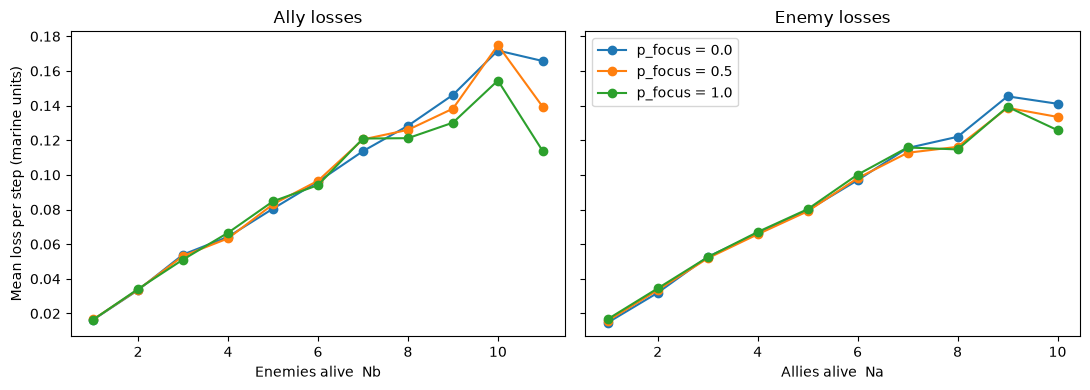

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for p, d in steps_train.groupby("p_focus"):
    axes[0].plot(d.groupby("Nb").dHa.mean().mul(-1), "o-", label=f"p_focus = {p}")
    axes[1].plot(d.groupby("Na").dHb.mean().mul(-1), "o-", label=f"p_focus = {p}")
axes[0].set(xlabel="Enemies alive  Nb", ylabel="Mean loss per step (marine units)", title="Ally losses")
axes[1].set(xlabel="Allies alive  Na", title="Enemy losses")
axes[1].legend(); plt.tight_layout(); plt.show()

## 5. Is the regression well-posed? Collinearity check

If two candidate variables move together, the regression can't tell which one causes the effect, and SINDy spreads weight across them (this is what produced the cancelling terms in earlier fits). Correlations close to ±1 between library columns are a warning sign. Mixing maps and doctrines should bring them down compared with 8m alone.

In [6]:
steps_train[["Ha", "Hb", "Na", "Nb"]].corr().round(2)

,Ha,Hb,Na,Nb
Ha,1.00,0.91,0.92,0.81
Hb,0.91,1.00,0.85,0.95
Na,0.92,0.85,1.00,0.80
Nb,0.81,0.95,0.80,1.00


## 6. SINDy fits, one per doctrine

`DiscreteSINDy` learns `x[k+1] = f(x[k], u[k])` from all training battles of a doctrine together. The library is degree 1 (constant, Ha, Hb, Na, Nb); STLSQ removes terms with coefficients below the threshold.

**What to look for:** `Ha[k+1] ≈ 1·Ha − β·Nb` and `Hb[k+1] ≈ 1·Hb − α·Na`. The coefficient near 1 is health carried over from the previous step; the other terms are the attrition. With health in marine units, β is the fraction of a marine removed per living enemy per step.

In [7]:
THRESHOLD = 0.01


def fit_sindy(keys, threshold=THRESHOLD, degree=1):
    model = ps.DiscreteSINDy(feature_library=ps.PolynomialLibrary(degree=degree),
                             optimizer=ps.STLSQ(threshold=threshold))
    model.fit([X[k] for k in keys], t=1, u=[U[k] for k in keys],
              feature_names=["Ha", "Hb", "Na", "Nb"])
    return model


def coef_table(model):
    return pd.DataFrame(model.coefficients(), index=["Ha[k+1]", "Hb[k+1]"],
                        columns=model.get_feature_names())


models = {}
for p in sorted(episodes.p_focus.unique()):
    keys = [k for k in train_keys if k[1] == p]
    models[p] = fit_sindy(keys)
    print(f"--- p_focus = {p}  ({len(keys)} battles)")
    models[p].print()
    print()

--- p_focus = 0.0  (700 battles)
(Ha)[k+1] =  0.991 Ha[k] +  0.017 Hb[k] + -0.023 Nb[k]
(Hb)[k+1] =  0.999 Hb[k] + -0.015 Na[k]

--- p_focus = 0.5  (700 battles)
(Ha)[k+1] =  0.995 Ha[k] +  0.014 Hb[k] + -0.024 Nb[k]
(Hb)[k+1] = -0.014 1 +  0.014 Ha[k] +  0.978 Hb[k] + -0.021 Na[k] +  0.016 Nb[k]

--- p_focus = 1.0  (700 battles)
(Ha)[k+1] =  1.000 Ha[k] + -0.016 Nb[k]
(Hb)[k+1] = -0.014 1 +  0.011 Ha[k] +  0.981 Hb[k] + -0.020 Na[k] +  0.016 Nb[k]



### Are the terms stable?

A term is only trustworthy if it survives small changes in the data. We refit on bootstrap resamples of the training battles and record how often each term is selected, and the spread of its coefficient. Terms selected in (almost) every resample are real structure; terms that come and go are fitting noise.

In [8]:
N_BOOT = 50
boot_rows = []
for p in sorted(episodes.p_focus.unique()):
    keys = [k for k in train_keys if k[1] == p]
    for b in range(N_BOOT):
        sample = [keys[i] for i in rng.integers(0, len(keys), len(keys))]
        c = coef_table(fit_sindy(sample)).stack().rename("coef").reset_index()
        c.columns = ["equation", "term", "coef"]
        c["p_focus"], c["boot"] = p, b
        boot_rows.append(c)
boot = pd.concat(boot_rows)

stability = (boot.groupby(["p_focus", "equation", "term"]).coef
                 .agg(selected=lambda v: (v != 0).mean(), mean="mean", std="std"))
stability[stability.selected > 0].round(3)

selected   mean    std
p_focus equation term                        
0.0     Ha[k+1]  Ha         1.0  0.991  0.000
                 Hb         1.0  0.017  0.001
                 Nb         1.0 -0.023  0.000
        Hb[k+1]  Hb         1.0  0.999  0.000
                 Na         1.0 -0.015  0.000
0.5     Ha[k+1]  Ha         1.0  0.995  0.000
                 Hb         1.0  0.014  0.001
                 Nb         1.0 -0.024  0.000
        Hb[k+1]  1          1.0 -0.014  0.001
                 Ha         1.0  0.014  0.000
                 Hb         1.0  0.978  0.001
                 Na         1.0 -0.021  0.000
                 Nb         1.0  0.016  0.000
1.0     Ha[k+1]  Ha         1.0  1.000  0.000
                 Nb         1.0 -0.016  0.000
        Hb[k+1]  1          1.0 -0.014  0.001
                 Ha         1.0  0.011  0.000
                 Hb         1.0  0.981  0.001
                 Na         1.0 -0.020  0.000
                 Nb         1.0  0.016  0.001

## 7. Testing the hypotheses directly

SINDy chooses terms from a general library. As a complement, we fit each hypothesis from the table at the top as a one-parameter model (least squares, no intercept) and compare their errors on the **test** battles. The model with the lowest test error is the best-supported explanation.

- **Square law** (aimed fire): ally loss ∝ Nb
- **Linear law** (area fire): ally loss ∝ Na·Nb
- **Pure decay**: ally loss ∝ Ha

In [9]:
def features(s, side):
    if side == "a":   # ally losses
        return {"square (Nb)": s.Nb, "linear (Na·Nb)": s.Na * s.Nb, "decay (Ha)": s.Ha}
    return {"square (Na)": s.Na, "linear (Na·Nb)": s.Na * s.Nb, "decay (Hb)": s.Hb}


rows, square_coef = [], {}
for p in sorted(episodes.p_focus.unique()):
    tr, te = steps_train[steps_train.p_focus == p], steps_test[steps_test.p_focus == p]
    for side, target in (("a", "dHa"), ("b", "dHb")):
        f_tr, f_te = features(tr, side), features(te, side)
        for name in f_tr:
            x, y = f_tr[name].to_numpy(), tr[target].to_numpy()
            c = (x @ y) / (x @ x)                        # least squares through the origin
            resid = te[target] - c * f_te[name]
            rows.append(dict(p_focus=p, equation="ally loss" if side == "a" else "enemy loss",
                             model=name, coef=c, test_rmse=np.sqrt((resid ** 2).mean())))
            if name.startswith("square"):
                square_coef[(p, side)] = -c              # effectiveness as a positive number

hyp = pd.DataFrame(rows)
display(hyp.pivot_table(index=["p_focus", "equation"], columns="model", values="test_rmse").round(4))

model               decay (Ha)  decay (Hb)  linear (Na·Nb)  square (Na)  \
p_focus equation                                                          
0.0     ally loss       0.1179         NaN          0.1168          NaN   
        enemy loss         NaN      0.0990          0.1002       0.0967   
0.5     ally loss       0.1027         NaN          0.1041          NaN   
        enemy loss         NaN      0.0977          0.1002       0.0949   
1.0     ally loss       0.0956         NaN          0.0982          NaN   
        enemy loss         NaN      0.0988          0.1022       0.0955   

model               square (Nb)  
p_focus equation                 
0.0     ally loss        0.1098  
        enemy loss          NaN  
0.5     ally loss        0.0984  
        enemy loss          NaN  
1.0     ally loss        0.0931  
        enemy loss          NaN

### Prediction: where does the win rate cross 50%?

With the square-law coefficients, α (ally effectiveness, from the enemy-loss equation) and β (enemy effectiveness, from the ally-loss equation), Lanchester predicts that the two sides are evenly matched at force ratio √(α/β). If the dashed lines land near where the measured win-rate curves cross 50%, the fitted coefficients mean something beyond the training data.

p_focus = 0.0:  alpha = 0.0156, beta = 0.0160, predicted break-even ratio = 0.99
p_focus = 0.5:  alpha = 0.0151, beta = 0.0158, predicted break-even ratio = 0.98
p_focus = 1.0:  alpha = 0.0151, beta = 0.0154, predicted break-even ratio = 0.99


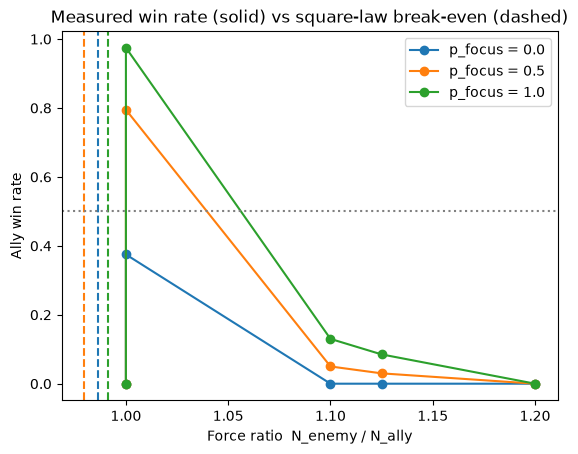

In [10]:
fig, ax = plt.subplots()
for i, (p, d) in enumerate(summary.groupby("p_focus")):
    alpha, beta = square_coef[(p, "b")], square_coef[(p, "a")]
    ratio = np.sqrt(alpha / beta)
    ax.plot(d.force_ratio, d.win_rate, "o-", color=f"C{i}", label=f"p_focus = {p}")
    ax.axvline(ratio, color=f"C{i}", ls="--")
    print(f"p_focus = {p}:  alpha = {alpha:.4f}, beta = {beta:.4f}, predicted break-even ratio = {ratio:.2f}")
ax.axhline(0.5, color="grey", ls=":")
ax.set(xlabel="Force ratio  N_enemy / N_ally", ylabel="Ally win rate",
       title="Measured win rate (solid) vs square-law break-even (dashed)")
ax.legend(); plt.show()

## 8. Validation by simulation

Two tests on held-out battles:

- **Open loop:** the model is given the *true* unit counts at every step and predicts the health curves. This tests the health equations on their own.
- **Closed loop:** the model gets only the starting state and plays out the whole battle. The unit counts come from a rule, alive = ⌈health⌉ in marine units, which is exact when damage is concentrated (focus fire) and underestimates the survivors when damage is spread (random targeting). This is the real prediction test.

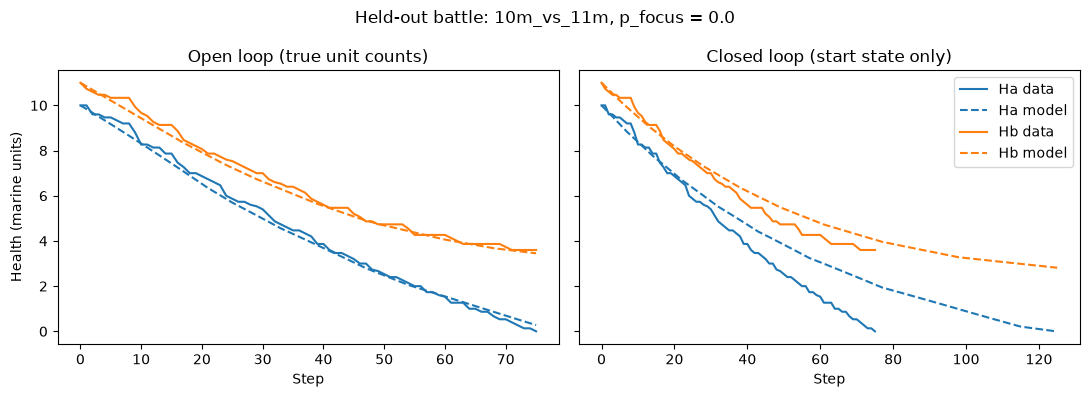

In [11]:
def closed_loop(model, x0, n_a, n_b, max_steps=500):
    x, traj = np.array(x0, float), [np.array(x0, float)]
    for _ in range(max_steps):
        u = np.array([min(np.ceil(max(x[0], 0)), n_a), min(np.ceil(max(x[1], 0)), n_b)])
        x = model.predict(x.reshape(1, -1), u=u.reshape(1, -1))[0]
        traj.append(x)
        if (x <= 0).any():
            break
    return np.array(traj)


k = test_keys[0]                                  # pick any held-out battle to plot
model = models[k[1]]
n_a, n_b = battles[k].Na.iloc[0], battles[k].Nb.iloc[0]
open_sim = model.simulate(X[k][0], t=len(X[k]), u=U[k])
closed_sim = closed_loop(model, X[k][0], n_a, n_b)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, sim, title in ((axes[0], open_sim, "Open loop (true unit counts)"),
                       (axes[1], closed_sim, "Closed loop (start state only)")):
    ax.plot(X[k][:, 0], "C0", label="Ha data"); ax.plot(sim[:, 0], "C0--", label="Ha model")
    ax.plot(X[k][:, 1], "C1", label="Hb data"); ax.plot(sim[:, 1], "C1--", label="Hb model")
    ax.set(xlabel="Step", title=title)
axes[0].set_ylabel("Health (marine units)"); axes[1].legend()
fig.suptitle(f"Held-out battle: {k[0]}, p_focus = {k[1]}"); plt.tight_layout(); plt.show()

### Closed-loop accuracy over all test battles

For every held-out battle: does the model predict the right winner, how much health does it predict the winner keeps, and how long does it predict the battle lasts?

In [12]:
res = []
for k in test_keys:
    d = battles[k]
    sim = closed_loop(models[k[1]], X[k][0], d.Na.iloc[0], d.Nb.iloc[0])
    true_ally_win = d.Nb.iloc[-1] == 0
    pred_ally_win = sim[-1, 1] <= 0
    res.append(dict(map=k[0], p_focus=k[1],
                    correct_winner=true_ally_win == pred_ally_win,
                    true_Ha_end=d.Ha.iloc[-1], pred_Ha_end=max(sim[-1, 0], 0),
                    true_Hb_end=d.Hb.iloc[-1], pred_Hb_end=max(sim[-1, 1], 0),
                    true_len=len(d), pred_len=len(sim)))
res = pd.DataFrame(res)
res["err_Ha_end"] = (res.pred_Ha_end - res.true_Ha_end).abs()
res["err_Hb_end"] = (res.pred_Hb_end - res.true_Hb_end).abs()
res["err_len"] = (res.pred_len - res.true_len).abs()

print(f"Overall winner accuracy: {res.correct_winner.mean():.2f}")
res.groupby(["p_focus", "map"])[["correct_winner", "err_Ha_end", "err_Hb_end", "err_len"]].mean().round(2)

Overall winner accuracy: 0.76


correct_winner  err_Ha_end  err_Hb_end  err_len
p_focus map                                                        
0.0     10m_vs_11m            1.00        0.00        1.01    53.37
        3m                    1.00        0.63        0.52    55.00
        5m_vs_6m              1.00        0.05        0.45    39.33
        8m                    0.55        0.33        0.73    51.53
        8m_vs_9m              1.00        0.00        0.88    55.53
0.5     10m_vs_11m            0.93        0.03        0.84    25.75
        3m                    1.00        0.83        0.96    50.00
        5m_vs_6m              1.00        0.52        0.86    32.05
        8m                    0.22        1.42        0.61    41.97
        8m_vs_9m              0.98        0.01        0.80    26.65
1.0     10m_vs_11m            0.82        0.19        2.49    19.27
        3m                    0.00        0.59        0.97    53.00
        5m_vs_6m              1.00        0.75        0.30    17.00
        8m                    0.02        2.29        1.10    43.98
        8m_vs_9m              0.90        0.13        1.78    11.15

## 9. Summary and next steps

Fill this in after running:

- **Structure:** Which terms does SINDy select for each doctrine, and are they stable across bootstrap resamples? Does the square law win the hypothesis comparison?
- **Coefficients:** How do α and β change with `p_focus`? Focus fire should raise α.
- **Break-even:** Does √(α/β) land near the measured 50% crossing?
- **Prediction:** Winner accuracy and errors in closed loop, and where they are worst (small maps? random targeting?).

Likely next steps:

1. Treat `p_focus` as a parameter inside one model (like the bifurcation parameter in Brunton et al., Sec. 3.3.3) instead of fitting one model per doctrine.
2. Add a feature for the number of units actually in range, to capture the partial engagement right after contact.
3. Replace the ⌈health⌉ rule for unit counts with something learned, especially for random targeting.
4. Compare against a neural-network surrogate on the same train/test split: accuracy, speed and extrapolation to unseen force ratios.